In [1]:
# %% Paso 1: Importación de paquetes ============================

# Rutas relativas
from pathlib import Path

# Manipulación de datos y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pruebas estadísticas y gráficos Q-Q de Scipy
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels (FAC/FACP, pruebas de diagnóstico y SARIMAX)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss


# %% Configuración de ruta relativa ============================

BASE_DIR = Path('.').resolve()
DATA_DIR = BASE_DIR / "datos"

print("Directorio raíz del proyecto:", BASE_DIR)
print("Carpeta de datos lista en:", DATA_DIR)





Directorio raíz del proyecto: C:\Users\USUARIO\OneDrive\Documentos\GitHub\Poster-econometria-II
Carpeta de datos lista en: C:\Users\USUARIO\OneDrive\Documentos\GitHub\Poster-econometria-II\datos


In [2]:
# Carga de la serie con ruta relativa
ruta_csv = DATA_DIR / "serie_economica.csv"

# Leer CSV parseando la columna de fechas de la FRED
df = pd.read_csv(ruta_csv, parse_dates=['observation_date'], index_col='observation_date')
df.columns = ['precio_gasolina']

# Convertir valores a numérico y eliminar nulos si existieran
df['precio_gasolina'] = pd.to_numeric(df['precio_gasolina'], errors='coerce')
df = df.dropna()

# Mostrar el total de observaciones
print(f"Número total de observaciones (T): {len(df)}")

# Visualizar las primeras filas del DataFrame
df.head()




Número total de observaciones (T): 1882


,precio_gasolina
observation_date,
1990-08-20,1.191
1990-08-27,1.245
1990-09-03,1.242
1990-09-10,1.252
1990-09-17,1.266


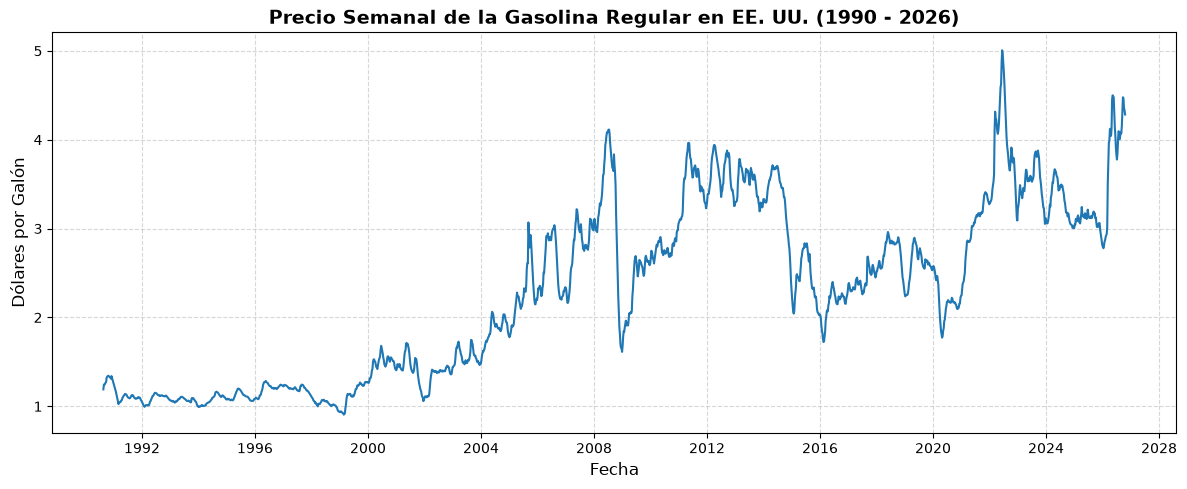

In [3]:
# %% =======================================================
# PASO 1: IDENTIFICACIÓN
# ==========================================================
# Graficar la serie de tiempo en niveles
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['precio_gasolina'], color='#1f77b4', linewidth=1.5)
plt.title('Precio Semanal de la Gasolina Regular en EE. UU. (1990 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Dólares por Galón', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()





In [4]:
#Mirando la gráfica se puede apreciar a simple vista que no tiene ni media ni varianza constante, por lo que no es estacionaria :o
#A continucación se aplicarán criterios para confirmar la hipótesis :D

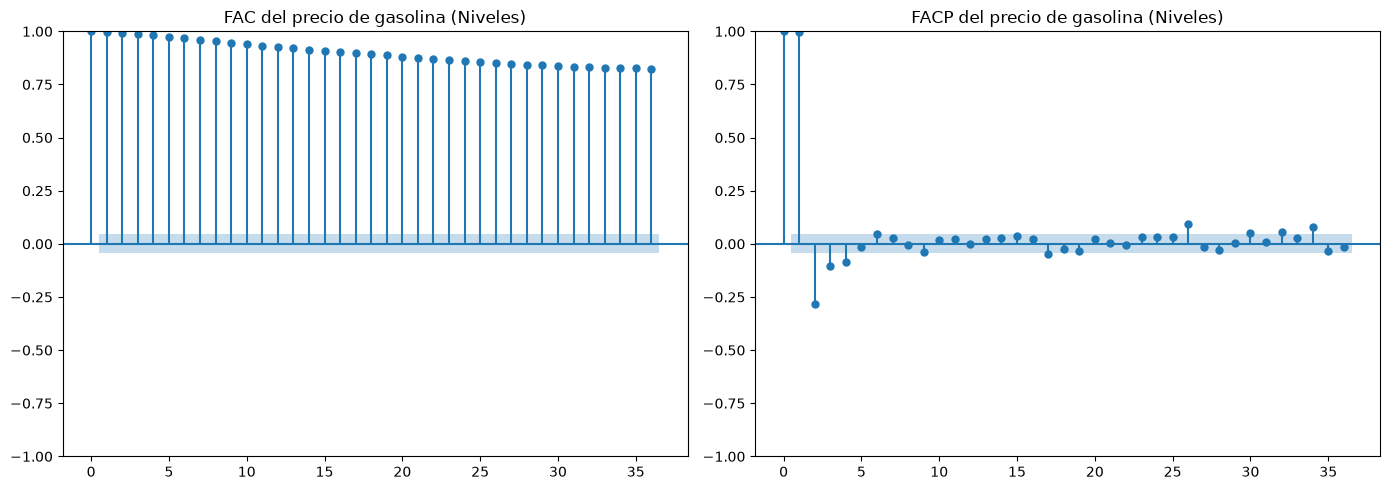

In [4]:
## %% FAC y FACP de la serie original =========================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    df['precio_gasolina'],
    lags=36,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)
axes[0].set_title("FAC del precio de gasolina (Niveles)")

plot_pacf(
    df['precio_gasolina'],
    lags=36,
    alpha=0.05,
    ax=axes[1]
)
axes[1].set_title("FACP del precio de gasolina (Niveles)")

plt.tight_layout()
plt.show()


In [5]:
# %% Tests de Raíz Unitaria (ADF y KPSS) =========================

# Test Augmented Dickey-Fuller (ADF)
adf_result = adfuller(df['precio_gasolina'])

print("=== Test ADF (Serie en Niveles) ===")
print("Estadístico ADF:", adf_result[0])
print("p-valor:", adf_result[1])
print("Rezagos usados:", adf_result[2])
for nivel, valor in adf_result[4].items():
    print(f"  Crítico {nivel}: {valor}")

if adf_result[1] < 0.05:
    print("ADF: Rechazamos H0 -> La serie es ESTACIONARIA.")
else:
    print("ADF: No rechazamos H0 -> La serie NO es estacionaria.")

# Test KPSS
kpss_result = kpss(df['precio_gasolina'], regression="c", nlags="auto")

print("\n=== Test KPSS (Serie en Niveles) ===")
print("Estadístico KPSS:", kpss_result[0])
print("p-valor:", kpss_result[1])
for nivel, valor in kpss_result[3].items():
    print(f"  Crítico {nivel}: {valor}")

if kpss_result[1] < 0.05:
    print("KPSS: Rechazamos H0 -> La serie NO es estacionaria.")
else:
    print("KPSS: No rechazamos H0 -> La serie es ESTACIONARIA.")
    
    

=== Test ADF (Serie en Niveles) ===
Estadístico ADF: -1.9352240027244718
p-valor: 0.31567630515245365
Rezagos usados: 9
  Crítico 1%: -3.4338480179204556
  Crítico 5%: -2.863085177979608
  Crítico 10%: -2.567592596439203
ADF: No rechazamos H0 -> La serie NO es estacionaria.

=== Test KPSS (Serie en Niveles) ===
Estadístico KPSS: 4.991310469082142
p-valor: 0.01
  Crítico 10%: 0.347
  Crítico 5%: 0.463
  Crítico 2.5%: 0.574
  Crítico 1%: 0.739
KPSS: Rechazamos H0 -> La serie NO es estacionaria.


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_1420\2552826971.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(df['precio_gasolina'], regression="c", nlags="auto")


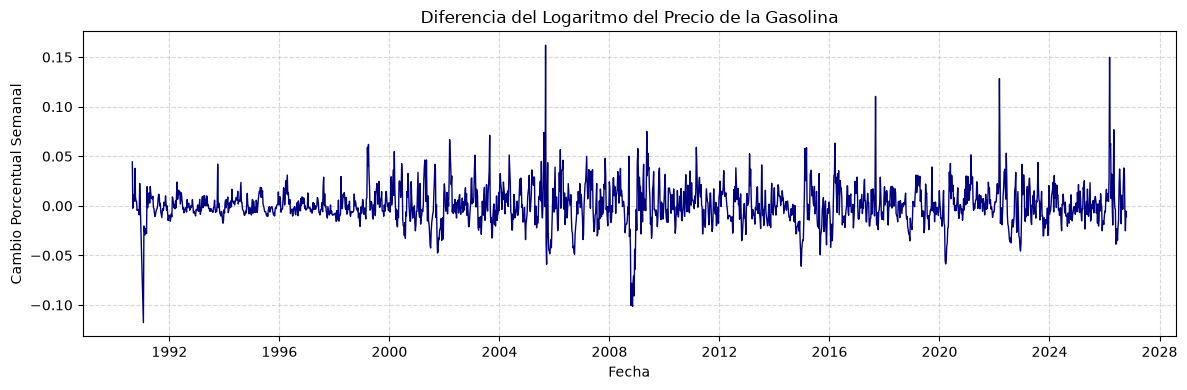

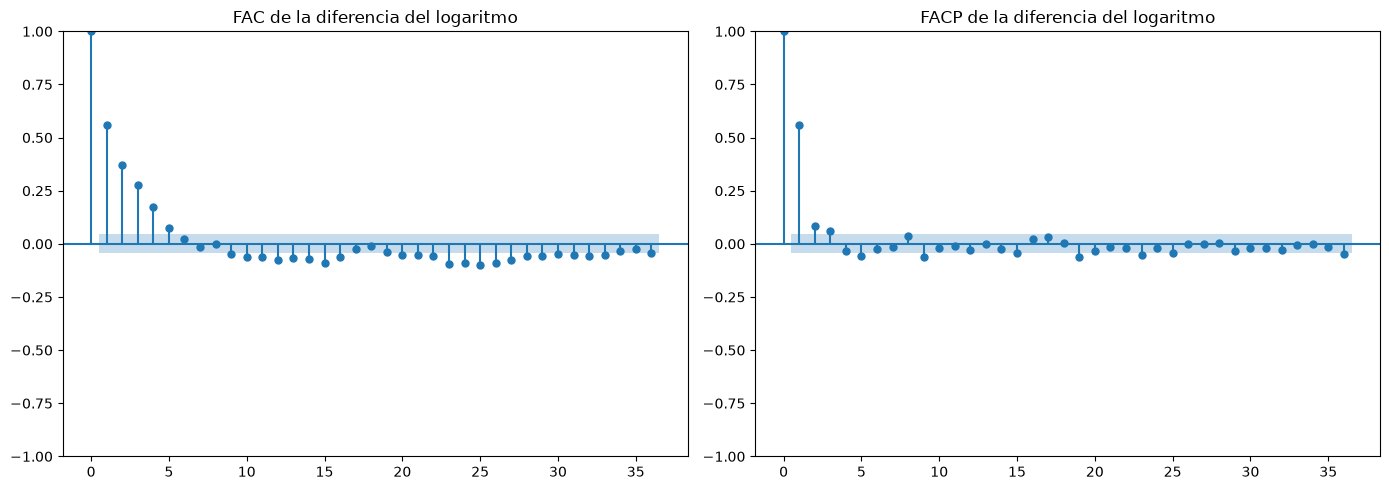

In [6]:
# Nota: Según los resultados de la prueba ADF y KPSS, hay que 
#       diferenciar la serie. Es una buena noticia que ambos resultados coincidieran.
# %% Serie transformada: Diferencia del Logaritmo =========================

# Crear las transformaciones en el DataFrame
df['log_gasolina'] = np.log(df['precio_gasolina'])
df['log_diff'] = df['log_gasolina'].diff()

# NOTA: Al diferenciar (.diff()), la primera observación queda como NaN (sin dato previo).
# Se aplica .dropna() únicamente para limpiar la serie antes de graficar la FAC/FACP y 
# realizar las pruebas ADF/KPSS, las cuales fallan ante valores nulos.

# Serie limpia para análisis
serie_estacionaria = df['log_diff'].dropna()

# Gráfico de la serie diferenciada
plt.figure(figsize=(12, 4))
plt.plot(serie_estacionaria, color='navy', linewidth=1)
plt.title("Diferencia del Logaritmo del Precio de la Gasolina")
plt.xlabel("Fecha")
plt.ylabel("Cambio Porcentual Semanal")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# FAC y FACP de la serie transformada para proponer ordenes p y q
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    serie_estacionaria,
    lags=36,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)
axes[0].set_title("FAC de la diferencia del logaritmo")

plot_pacf(
    serie_estacionaria,
    lags=36,
    alpha=0.05,
    ax=axes[1]
)
axes[1].set_title("FACP de la diferencia del logaritmo")

plt.tight_layout()
plt.show()



In [12]:
# %% Identificación del modelo usando FAC y FACP

# La FAC muestra un decaimiento progresivo (suave / geométrico).
# La FACP presenta un corte abrupto en el primer rezago.
# Por tanto, se propone inicialmente un modelo AR(1) sobre la serie
# transformada, equivalente a un ARIMA(1, 1, 0) sobre log(precio_gasolina).

# P.d. También se puede considerar un modelo alternativo ARIMA(2, 1, 0)
#      dado el segundo rezago de la FACP, y comparar mediante los
#      criterios de información (AIC y BIC) en la etapa de estimación.
#      por si las moscas pondremos un modelo ARIMA(1, 1, 1). Spoiler: Las moscas resultaron ser ciertas xD.
#p.d 2: En caso de tener un ARIMA (1, 1, 0) puro genera un decaimiento exponencial teórico estrictamente positivo. 
#      Si fuera un ARIMA (2, 1, 0) evalúa si esa oscilación de la FAC requiere coeficientes con raíces complejas para un mejor ajuste (AIC/BIC)



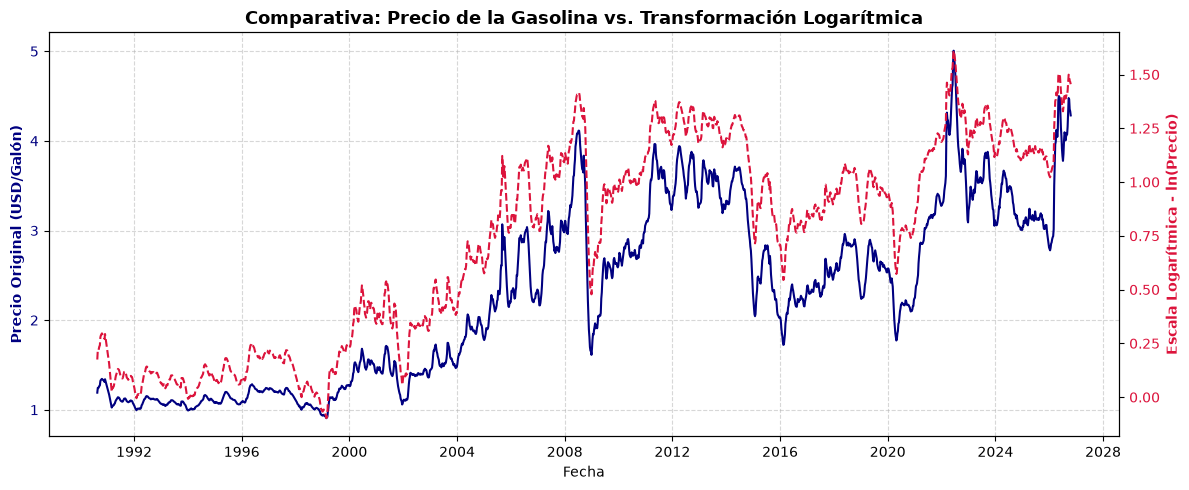

In [7]:
# %% Comparativa entre la serie original y la transformada en logaritmo
fig, ax1 = plt.subplots(figsize=(12, 5))

# 1. Serie original en el primer eje Y (Eje izquierdo - Azul)
color1 = 'navy'
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Precio Original (USD/Galón)', color=color1, fontweight='bold')
ax1.plot(df.index, df['precio_gasolina'], color=color1, linewidth=1.5, label='Precio Original')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Serie en logaritmo en el segundo eje Y (Eje derecho - Rojo)
ax2 = ax1.twinx()
color2 = 'crimson'
ax2.set_ylabel('Escala Logarítmica - ln(Precio)', color=color2, fontweight='bold')
ax2.plot(df.index, np.log(df['precio_gasolina']), color=color2, linewidth=1.5, linestyle='--', label='Log(Precio)')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Comparativa: Precio de la Gasolina vs. Transformación Logarítmica', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()


In [ ]:
#¿Qué puedo decir? Visualmente la comparación permite identificar la amortiguación de los picos que presentan una extrema volatilidad.....Me atrevería a relacionarlo con la crisis financiera de 2008 o la inflación de 2022)#

In [8]:
# %% =======================================================
# PASO 2: ESTIMACIÓN Y TABLA COMPARATIVA DE MODELOS
# ==========================================================
from statsmodels.iolib.summary2 import summary_col

# 1. Definir la serie en logaritmo (SARIMAX aplica la diferencia con d=1)
log_gasolina = np.log(df['precio_gasolina'])

# 2. Estimación de los modelos candidatos
mod_110 = SARIMAX(log_gasolina, order=(1, 1, 0), trend='n').fit(disp=False)
mod_210 = SARIMAX(log_gasolina, order=(2, 1, 0), trend='n').fit(disp=False)
mod_111 = SARIMAX(log_gasolina, order=(1, 1, 1), trend='n').fit(disp=False)

# 3. Diccionario con métricas de información (AIC y BIC)
info_metricas = {
    'Observaciones': lambda x: f"{int(x.nobs)}",
    'AIC': lambda x: f"{x.aic:.2f}",
    'BIC': lambda x: f"{x.bic:.2f}"
}

# 4. Construcción de la tabla comparativa estilo artículo
tabla_comparativa = summary_col(
    results=[mod_110, mod_210, mod_111],
    model_names=['ARIMA(1,1,0)', 'ARIMA(2,1,0)', 'ARIMA(1,1,1)'],
    stars=True,             # Muestra las estrellas de significancia (*, **, ***)
    float_format='%0.4f',   # Muestra 4 decimales en los coeficientes
    info_dict=info_metricas # Agrega AIC y BIC
)

print("=== TABLA COMPARATIVA DE MODELOS CANDIDATOS ===")
print(tabla_comparativa)



C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init

=== TABLA COMPARATIVA DE MODELOS CANDIDATOS ===

              ARIMA(1,1,0) ARIMA(2,1,0) ARIMA(1,1,1)
----------------------------------------------------
ar.L1         0.5613***    0.5170***    0.6701***   
              (0.0094)     (0.0103)     (0.0212)    
sigma2        0.0003***    0.0003***    0.0003***   
              (0.0000)     (0.0000)     (0.0000)    
ar.L2                      0.0818***                
                           (0.0140)                 
ma.L1                                   -0.1578***  
                                        (0.0243)    
AIC           -10149.82    -10160.48    -10162.88   
BIC           -10138.74    -10143.86    -10146.26   
Observaciones 1882         1882         1882        
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


In [14]:
# Nota sobre la interpretación de los resultados:
# Si nos fijamos en los parámetros de los tres modelos (tanto AR como MA): Todos cumplen con un p-value < 0.01 
# (¡todas las variables son significativas para los modelos! ;D). 
# Al revisar los criterios de información (AIC y BIC) junto con el principio de parsimonia, el modelo ganador 
# resultó ser el ARIMA(1,1,1), ya que logra los valores más bajos (más negativos: AIC -10162.88 y BIC -10146.26) 
# y todos sus componentes aportan información relevante al proceso.

In [16]:
#Nota aclaratoria 2: 
# NOTA SOBRE LA EVOLUCIÓN DEL MODELO (Identificación vs. Estimación):
# Inicialmente, el corte en el primer rezago de la FACP sugería un modelo AR(1) puro (ARIMA(1,1,0)).
# Sin embargo, aplicando la metodología Box-Jenkins de forma rigurosa, se contrastó esta hipótesis
# inicial frente a candidatos alternativos. 
# 
# Los resultados muestran que la estructura AR(1) sigue siendo la base del modelo (ar.L1 = 0.6701***),
# pero la adición de un término de media móvil MA(1) en el ARIMA(1,1,1) permite capturar los shocks de
# corto plazo, logrando los menores criterios AIC y BIC. 


=== DESCRIPCIÓN DE LOS RESIDUALES ===
count    1882.000000
mean        0.000354
std         0.016710
min        -0.128579
25%        -0.007999
50%        -0.000639
75%         0.007418
max         0.174793
dtype: float64




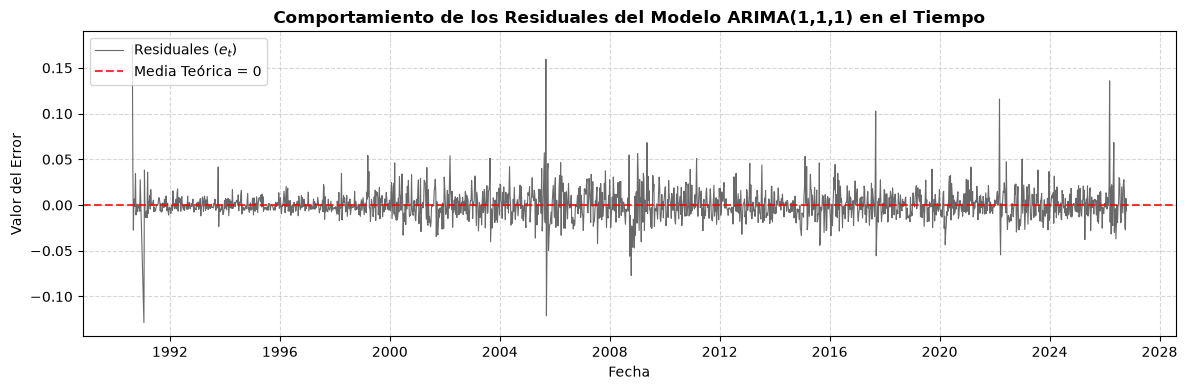

In [9]:
# %% =======================================================
# PASO 3: VALIDACIÓN DE SUPUESTOS / DIAGNÓSTICO DE RESIDUALES
# MODELO GANADOR: ARIMA(1,1,1)
# ==========================================================
# 1. Extracción de los residuales del modelo ganador
residuos = mod_111.resid.dropna()
residuos_cuadrado = residuos ** 2

print("=== DESCRIPCIÓN DE LOS RESIDUALES ===")
print(residuos.describe())
print("\n" + "="*50 + "\n")

# ----------------------------------------------------------
# A. Gráfico de Comportamiento Temporal de Residuales
# ----------------------------------------------------------
plt.figure(figsize=(12, 4))
plt.plot(residuos, color='dimgray', linewidth=0.8, label='Residuales ($e_t$)')
plt.axhline(0, color='red', linestyle='--', alpha=0.8, linewidth=1.5, label='Media Teórica = 0')
plt.title('Comportamiento de los Residuales del Modelo ARIMA(1,1,1) en el Tiempo', fontsize=12, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Valor del Error')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


In [ ]:
#Comentarios: Los residuos del modelo ARIMA (1, 1, 1) presentan una media que tiende bastante a cero, permitiendo la validación del supuesto de insesgadez (E(et)=0).
#Además, si se analiza el gráfico se evidencia un comportamiento oscilatorio centrado alrededor de cero, donde las fluctuaciones atípicas responden a shocks exógenos puntuales característicos del mercado de combustibles.

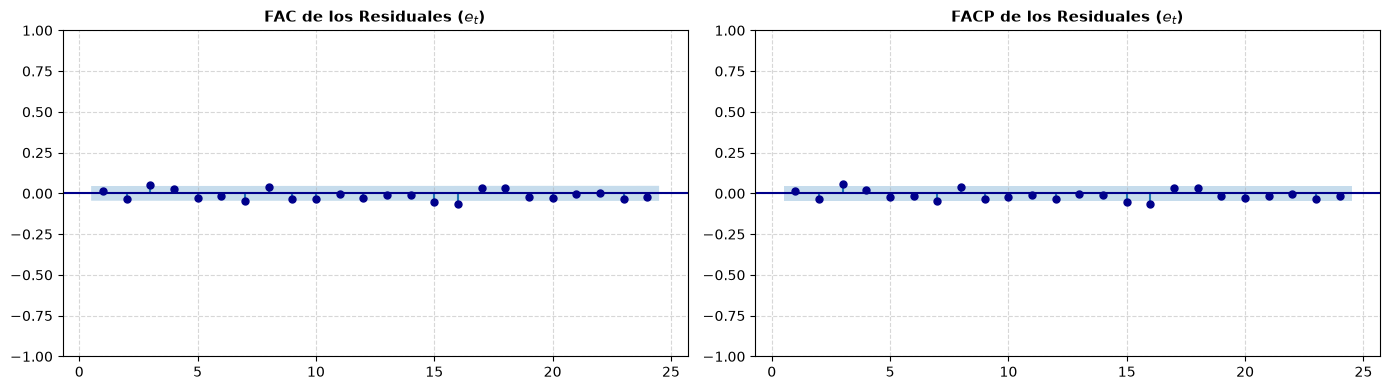

In [10]:
# ----------------------------------------------------------
# B. FAC y FACP de los Residuales (Independencia)
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(residuos, lags=24, zero=False, ax=axes[0], color='darkblue')
axes[0].set_title("FAC de los Residuales ($e_t$)", fontsize=11, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

plot_pacf(residuos, lags=24, zero=False, ax=axes[1], color='darkblue')
axes[1].set_title("FACP de los Residuales ($e_t$)", fontsize=11, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
#Comentarios: Analizando la FAC y FACP de los residuos, observamos que todos los rezagos se ubican dentro de las bandas de confianza del 95%, 
#lo que demuestra empíricamente la ausencia de autocorrelación residual y confirma que el modelo logró extraer toda la dinámica temporal de la serie,
#teniendo en cuenta que se trabaja con ruido blanco. (Este resultado es bastante positivo) :D